<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5c_dualcomplexos_edo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V (c): poses que se movem

## Velocidades no corpo, a nave do Asteroids, o colchete de Lie no integrador e a banana da odometria

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 5](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb)) · **Anterior:** [X5b_dualcomplexos_sistemas.ipynb](X5b_dualcomplexos_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5b_dualcomplexos_sistemas.ipynb)) · **Próximo:** [X5d_dualcomplexos_perseguicao.ipynb](X5d_dualcomplexos_perseguicao.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5d_dualcomplexos_perseguicao.ipynb))

**Objetivo.** Integrar o movimento de um corpo rígido no plano, cuja pose $q(t)$ é um dual-complexo unitário. As velocidades de um corpo (a de giro $\omega$ e a de translação $v$) são naturalmente medidas **no próprio corpo**: o empuxo de uma nave aponta para a frente da nave, a odometria de um robô mede o quanto as rodas andaram. A equação da pose é

$$\dot q=q\,X(t),\qquad X=(\omega,v)\ \text{no referencial do corpo}.$$

Três lições:
- **o colchete de Lie aparece.** Integrar $\dot q=qX(t)$ por passos $q\leftarrow q\,\mathrm{Exp}(\cdot)$ exige, a partir da ordem 3, um termo de correção que mede o quanto as velocidades em instantes diferentes não comutam: o colchete $[X_1,X_2]$. Sem ele, um método que seria de ordem 4 cai para ordem 2. É a primeira vez na série que a não comutatividade muda o resultado de um integrador;
- **a nave do *Asteroids*:** empuxo para a frente, torque para girar, e a trajetória que sai disso;
- **a banana da odometria:** um robô que anda sem referência externa acumula uma incerteza com forma de banana. Uma gaussiana nas coordenadas $(x,y,\theta)$ descreve mal essa nuvem; uma gaussiana nas **coordenadas exponenciais** do grupo, $q=\hat q\,\mathrm{Exp}(\xi)$, descreve muito melhor.

**Roteiro**
1. Velocidades no corpo, $\dot q=qX$ e o colchete de Lie
2. Integradores no grupo: Euler, ponto médio, Magnus de ordem 4, e o que acontece sem o colchete
3. A nave do *Asteroids*
4. A banana da odometria
5. Espaço de estados para a etapa (d): o erro no corpo e o erro no mundo
6. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

from scipy.integrate import solve_ivp
rng = np.random.default_rng(53)

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))


def Ad(q):
    """Matriz 3×3 de Ad_q em coordenadas (ω, v_x, v_y): q·Exp(ξ)·q⁻¹ = Exp(Ad_q ξ)."""
    th, t = angulo(q), translacao(q); c_, s_ = np.cos(th), np.sin(th)
    return np.array([[1, 0, 0], [t.imag, c_, -s_], [-t.real, s_, c_]])

def Log3(q):
    w, v = Log(q); return np.array([w, v.real, v.imag])

def Exp3(xi):
    return Exp(xi[0], xi[1] + 1j * xi[2])

---

## 1. Velocidades no corpo, $\dot q=qX$ e o colchete de Lie

Se o corpo se move com velocidade constante $X=(\omega,v)$ no próprio referencial, depois de um tempo $t$ a pose é $q_0\,\mathrm{Exp}(tX)$: o arco de círculo do notebook V(a). Derivando em $t=0$, $\mathrm{Exp}(tX)\approx1+\tfrac t2(i\omega+v\,\varepsilon)$, e a equação da pose, com $X$ variando no tempo, é

$$\dot q=q\cdot\tfrac12\big(i\,\omega(t)+v(t)\,\varepsilon\big).$$

A multiplicação é **à direita** porque as velocidades estão no referencial do corpo: a velocidade de hoje é aplicada depois de tudo o que já aconteceu.

**O colchete de Lie.** Em $SE(2)$, a ordem dos movimentos importa (notebook V(a)). Uma medida de quanto dois movimentos pequenos não comutam é o **comutador de grupo**: andar $sX_1$, depois $sX_2$, depois desfazer $sX_1$, depois desfazer $sX_2$. Se tudo comutasse, voltaria ao começo; em $SE(2)$, sobra um deslocamento da ordem de $s^2$:

$$\mathrm{Exp}(sX_1)\,\mathrm{Exp}(sX_2)\,\mathrm{Exp}(-sX_1)\,\mathrm{Exp}(-sX_2)\approx\mathrm{Exp}\big(s^2[X_1,X_2]\big),\qquad[X_1,X_2]=\big(0,\ i(\omega_1v_2-\omega_2v_1)\big).$$

O colchete não tem giro (os giros comutam entre si); tem só translação, perpendicular às velocidades (o fator $i$). É a "manobra de estacionamento": frente, gira, ré, desgira, e o carro andou **de lado**. A célula confere a fórmula com o comutador de grupo calculado com dual-complexos.

In [2]:
def colchete(X1, X2):
    """[X1, X2] em se(2), com X = (ω, v), v complexo."""
    return (0.0, 1j * (X1[0] * X2[1] - X2[0] * X1[1]))

X1, X2 = (0.3, 0.5 + 0.2j), (-0.4, 0.1 - 0.7j)
for s in [1e-2, 1e-3, 1e-4]:
    g = Exp(s * X1[0], s * X1[1]) * Exp(s * X2[0], s * X2[1]) * Exp(-s * X1[0], -s * X1[1]) * Exp(-s * X2[0], -s * X2[1])
    w_, v_ = Log(g)
    print(f"s = {s:.0e}:  Log(comutador)/s² = ({w_ / s**2:+.6f}, {v_ / s**2:.6f})")
print("colchete pela fórmula:               ", colchete(X1, X2))
confere("Log(comutador)/s² → [X1, X2] (o resto é da ordem de s)", v_ / 1e-8, colchete(X1, X2)[1], tol=1e-5)

# a manobra de estacionamento: frente, gira, ré, desgira
frente, gira = (0.0, 1.0 + 0j), (0.5, 0j)
q = Exp(*frente) * Exp(*gira) * Exp(-frente[0], -frente[1]) * Exp(-gira[0], -gira[1])
print(f"\nfrente 1 m, gira 0,5 rad, ré 1 m, desgira: o carro termina em {translacao(q):.4f}, com ângulo {angulo(q):.1e}")
print(f"   (o colchete prevê um deslocamento lateral de {colchete(frente, gira)[1]:.4f}, para s = 1 a fórmula é só a primeira aproximação)")

s = 1e-02:  Log(comutador)/s² = (+0.000000, 0.130115+0.229935j)
s = 1e-03:  Log(comutador)/s² = (+0.000000, 0.130011+0.229993j)
s = 1e-04:  Log(comutador)/s² = (+0.000000, 0.130001+0.229999j)
colchete pela fórmula:                (0.0, (0.12999999999999998+0.23j))
OK   Log(comutador)/s² → [X1, X2] (o resto é da ordem de s):  diferença máxima = 1.32e-06

frente 1 m, gira 0,5 rad, ré 1 m, desgira: o carro termina em 0.1224-0.4794j, com ângulo 0.0e+00
   (o colchete prevê um deslocamento lateral de -0.0000-0.5000j, para s = 1 a fórmula é só a primeira aproximação)


---

## 2. Integradores no grupo

Suponha que as velocidades no corpo são conhecidas em cada instante (medidas pela odometria, por exemplo):
$$\omega(t)=0{,}8\sin(1{,}3t)+0{,}4,\qquad v(t)=1+0{,}5\cos(0{,}9t)+0{,}3i\sin(0{,}7t).$$
Quatro maneiras de avançar a pose de $t$ a $t+h$ multiplicando por uma $\mathrm{Exp}$ (todas ficam no grupo por construção):
- **Euler no grupo:** $q\leftarrow q\,\mathrm{Exp}\big(hX(t)\big)$. Ordem 1.
- **ponto médio:** $q\leftarrow q\,\mathrm{Exp}\big(hX(t+h/2)\big)$. Ordem 2.
- **Magnus de ordem 4** (com dois pontos de Gauss, $t_{1,2}=t+(\tfrac12\mp\tfrac{\sqrt3}6)h$):
$$q\leftarrow q\,\mathrm{Exp}\Big(\tfrac h2(X_1+X_2)+\tfrac{\sqrt3}{12}h^2\,[X_1,X_2]\Big).$$
- **o mesmo, sem o colchete:** $q\leftarrow q\,\mathrm{Exp}\big(\tfrac h2(X_1+X_2)\big)$.

E duas fora do grupo, para comparar:
- **RK4 nas coordenadas** $(x,y,\theta)$: $\dot x+i\dot y=e^{i\theta}v$, $\dot\theta=\omega$;
- **RK4 nas quatro componentes do dual-complexo**, aplicado a $\dot q=q\cdot\tfrac12(i\omega+v\varepsilon)$ como se fosse uma EDO qualquer em $\mathbb R^4$.

A referência é uma solução do `scipy` com tolerância de $10^{-13}$, depois de 10 s.

In [3]:
w_t = lambda t: 0.8 * np.sin(1.3 * t) + 0.4
v_t = lambda t: (1.0 + 0.5 * np.cos(0.9 * t)) + 0.3j * np.sin(0.7 * t)
T_I = 10.0

def f_coord(t, s):
    vv = np.exp(1j * s[2]) * v_t(t)
    return np.array([vv.real, vv.imag, w_t(t)])
ref = solve_ivp(f_coord, (0, T_I), [0, 0, 0], method="DOP853", rtol=1e-13, atol=1e-13).y[:, -1]
ref_p, ref_th = ref[0] + 1j * ref[1], ref[2]

def no_grupo(h, metodo):
    q = pose(0.0, 0j)
    for k in range(int(round(T_I / h))):
        t = k * h
        if metodo == "Euler no grupo":
            W, V = h * w_t(t), h * v_t(t)
        elif metodo == "ponto médio":
            W, V = h * w_t(t + h / 2), h * v_t(t + h / 2)
        else:
            t1, t2 = t + (0.5 - np.sqrt(3) / 6) * h, t + (0.5 + np.sqrt(3) / 6) * h
            Xa, Xb = (w_t(t1), v_t(t1)), (w_t(t2), v_t(t2))
            W, V = h / 2 * (Xa[0] + Xb[0]), h / 2 * (Xa[1] + Xb[1])
            if metodo == "Magnus 4 (com colchete)":
                cb = colchete(Xa, Xb)
                W, V = W + np.sqrt(3) / 12 * h * h * cb[0], V + np.sqrt(3) / 12 * h * h * cb[1]
        q = q * Exp(W, V)
    return translacao(q), angulo(q), np.sqrt(q.norma2())

def rk4_coord(h):
    s = np.zeros(3)
    for k in range(int(round(T_I / h))):
        t = k * h
        k1 = f_coord(t, s); k2 = f_coord(t + h / 2, s + h / 2 * k1); k3 = f_coord(t + h / 2, s + h / 2 * k2); k4 = f_coord(t + h, s + h * k3)
        s = s + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return s[0] + 1j * s[1], s[2], 1.0

def rk4_componentes(h):
    def f(t, q):
        X = DC(0.0, w_t(t) / 2, v_t(t).real / 2, v_t(t).imag / 2)
        return q * X
    q = pose(0.0, 0j)
    for k in range(int(round(T_I / h))):
        t = k * h
        k1 = f(t, q); k2 = f(t + h / 2, q + k1 * (h / 2)); k3 = f(t + h / 2, q + k2 * (h / 2)); k4 = f(t + h, q + k3 * h)
        q = q + (k1 + k2 * 2 + k3 * 2 + k4) * (h / 6)
    return translacao(q), angulo(q), np.sqrt(q.norma2())

hs = np.array([0.2, 0.1, 0.05, 0.025])
metodos = {m: (lambda h, m=m: no_grupo(h, m)) for m in ["Euler no grupo", "ponto médio", "Magnus 4 sem colchete", "Magnus 4 (com colchete)"]}
metodos["RK4 nas coordenadas"] = rk4_coord
metodos["RK4 nas componentes do dual-complexo"] = rk4_componentes
ordens = {}
print(f"{'método':38s} erro (h = 0,025)   ordem   |a| − 1 no fim (h = 0,2)")
for nome, fn in metodos.items():
    erros = [abs(fn(h)[0] - ref_p) for h in hs]
    ordens[nome] = np.polyfit(np.log(hs), np.log(erros), 1)[0]
    print(f"{nome:38s} {erros[-1]:14.2e}   {ordens[nome]:5.2f}   {fn(0.2)[2] - 1:+.1e}")
confere("Magnus 4 com colchete tem ordem 4", ordens["Magnus 4 (com colchete)"], 4.0, tol=0.1)
confere("sem o colchete, cai para ordem 2", ordens["Magnus 4 sem colchete"], 2.0, tol=0.1)

método                                 erro (h = 0,025)   ordem   |a| − 1 no fim (h = 0,2)
Euler no grupo                               2.11e-02    0.97   +0.0e+00
ponto médio                                  8.66e-05    2.00   +2.2e-16
Magnus 4 sem colchete                        1.96e-04    2.00   -5.6e-16
Magnus 4 (com colchete)                      5.15e-09    4.00   -5.6e-16
RK4 nas coordenadas                          8.40e-09    4.00   +0.0e+00
RK4 nas componentes do dual-complexo         4.64e-09    3.98   -2.9e-07
OK   Magnus 4 com colchete tem ordem 4:  diferença máxima = 9.37e-05
OK   sem o colchete, cai para ordem 2:  diferença máxima = 1.20e-03


**Leitura.**
- Euler e ponto médio têm as ordens esperadas, 1 e 2.
- O método de Magnus com dois pontos de Gauss tem ordem **4 com o colchete e 2 sem ele**. O termo $\tfrac{\sqrt3}{12}h^2[X_1,X_2]$ parece pequeno, mas é ele que compensa o fato de as velocidades em $t_1$ e $t_2$ não comutarem. Nos domínios I a IV, o colchete era zero, e o RKMK era o RK4 com outro nome (notebooks III(c) e IV(c)). Aqui, deixa de ser.
- O RK4 nas coordenadas $(x,y,\theta)$ também tem ordem 4, e funciona bem: $SE(2)$ tem coordenadas globais sem singularidades, e o ângulo não precisa de cuidado se não for enrolado. A vantagem dos integradores no grupo aparece nos domínios VI a VIII, em que as coordenadas de uma rotação no espaço têm singularidades.
- O RK4 aplicado às quatro componentes do dual-complexo tem ordem 4 na posição, mas **sai do grupo**: $\lvert a\rvert$ deixa de ser 1 (a última coluna), como o complexo unitário encolhia no notebook IV(c). Os métodos no grupo ficam com $\lvert a\rvert=1$ até o arredondamento.

---

## 3. A nave do *Asteroids*

Uma nave no espaço (sem atrito, sem gravidade) tem um motor que empurra **para a frente** e propulsores que a fazem **girar**. As equações de Newton, escritas no referencial da nave (com $v$ complexo, a velocidade no corpo), são

$$m\,(\dot v+i\omega v)=F,\qquad J\,\dot\omega=\tau .$$

O termo $i\omega v$ aparece porque o referencial gira (é o Coriolis do notebook IV(c), no referencial do corpo): se a nave gira sem empuxo, a velocidade **no corpo** gira para o outro lado, enquanto a velocidade no mundo fica constante. A célula integra as velocidades com RK4 (elas não dependem da pose) e a pose com o Magnus de ordem 4, durante uma sequência de comandos: empurrar, girar, empurrar de novo. Confere que, sem empuxo, a velocidade **no mundo** se conserva.

velocidade no mundo entre 4,2 s e 5,9 s (sem empuxo): de -0.000000+3.996667j a -0.000000+3.996667j
OK   sem empuxo, a velocidade no mundo se conserva:  diferença máxima = 4.25e-09


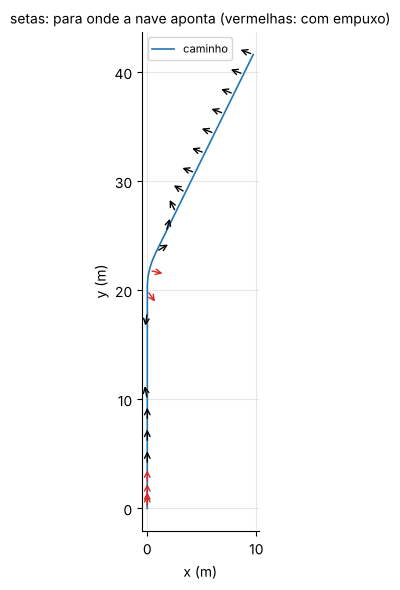

In [4]:
M_NAVE, J_NAVE = 1.0, 0.2
def comandos(t):
    F = 2.0 if (t < 2.0 or 6.0 <= t < 7.0) else 0.0           # empuxo (N), para a frente
    tau = 0.3 if 3.0 <= t < 4.0 else (-0.3 if 8.0 <= t < 9.0 else 0.0)
    return F, tau

def f_vel(t, s):
    v, w = s[0] + 1j * s[1], s[2]
    F, tau = comandos(t)
    dv = F / M_NAVE - 1j * w * v
    return np.array([dv.real, dv.imag, tau / J_NAVE])

h = 0.01
q, s, t = pose(np.pi / 2, 0j), np.zeros(3), 0.0
caminho, v_mundo, angulos = [translacao(q)], [], [angulo(q)]
while t < 12.0 - 1e-9:
    # velocidades: RK4 com os nós de Gauss guardados para o Magnus
    k1 = f_vel(t, s); k2 = f_vel(t + h / 2, s + h / 2 * k1); k3 = f_vel(t + h / 2, s + h / 2 * k2); k4 = f_vel(t + h, s + h * k3)
    s_novo = s + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    s1 = s + (0.5 - np.sqrt(3) / 6) * (s_novo - s); s2 = s + (0.5 + np.sqrt(3) / 6) * (s_novo - s)   # interpolação linear nos nós
    Xa, Xb = (s1[2], s1[0] + 1j * s1[1]), (s2[2], s2[0] + 1j * s2[1])
    cb = colchete(Xa, Xb)
    q = q * Exp(h / 2 * (Xa[0] + Xb[0]) + np.sqrt(3) / 12 * h * h * cb[0], h / 2 * (Xa[1] + Xb[1]) + np.sqrt(3) / 12 * h * h * cb[1])
    s, t = s_novo, t + h
    caminho.append(translacao(q)); angulos.append(angulo(q)); v_mundo.append(np.exp(1j * angulo(q)) * (s[0] + 1j * s[1]))
caminho, v_mundo = np.array(caminho), np.array(v_mundo)
ts = np.arange(1, len(v_mundo) + 1) * h
sem_empuxo = (ts > 4.2) & (ts < 5.9)                           # trecho em que a nave só gira (e depois desliza)
print(f"velocidade no mundo entre 4,2 s e 5,9 s (sem empuxo): de {v_mundo[sem_empuxo][0]:.6f} a {v_mundo[sem_empuxo][-1]:.6f}")
confere("sem empuxo, a velocidade no mundo se conserva", np.max(np.abs(v_mundo[sem_empuxo] - v_mundo[sem_empuxo][0])), 0, tol=1e-6)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(caminho.real, caminho.imag, lw=1.2, label="caminho")
for k in range(0, len(caminho), 50):                         # a cada 0,5 s, uma seta para onde a nave aponta
    p_, d_ = caminho[k], 1.5 * np.exp(1j * angulos[k])
    ax.annotate("", xy=(p_.real + d_.real, p_.imag + d_.imag), xytext=(p_.real, p_.imag),
                arrowprops={"arrowstyle": "->", "color": "tab:red" if comandos(k * h)[0] > 0 else "k"})
ax.legend(fontsize=8)
ax.set_aspect("equal"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title("setas: para onde a nave aponta (vermelhas: com empuxo)", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** Entre os comandos, a nave desliza em linha reta com velocidade constante no mundo, mesmo enquanto gira: girar não muda para onde ela vai, só para onde ela aponta. É a física que torna o *Asteroids* difícil de jogar, e que obriga a girar a nave de costas para frear. No referencial da nave, a mesma velocidade constante aparece girando, por causa do termo $i\omega v$.

---

## 4. A banana da odometria

Um robô anda em linha reta a 1 m/s por 20 s, sem nenhuma referência externa, contando só com a odometria: a velocidade de avanço e a de giro, medidas com ruído. O erro no giro se acumula no ângulo, e o erro no ângulo se transforma em erro lateral, tanto maior quanto mais longe o robô vai. A nuvem das posições finais possíveis tem a forma de uma **banana**: um arco de círculo, porque o robô anda sempre a mesma distância, só que em direções diferentes.

Duas gaussianas tentam descrever essa nuvem, cada uma propagada pelo seu filtro de Kalman:
- **nas coordenadas** $(x,y,\theta)$, com o EKF clássico: uma elipse no plano;
- **nas coordenadas exponenciais:** $q=\hat q\,\mathrm{Exp}(\xi)$, com $\xi$ gaussiano. A covariância de $\xi$ se propaga com a matriz adjunta (seção 5): $\Sigma\leftarrow\mathrm{Ad}_{\mathrm{Exp}(-u)}\,\Sigma\,\mathrm{Ad}_{\mathrm{Exp}(-u)}^\top+\mathbf Q$.

A figura sorteia pontos de cada gaussiana e os compara com 3000 trajetórias simuladas. A tabela mede a **cobertura**: a fração das trajetórias simuladas que caem dentro da região de 95% de cada gaussiana (a distância de Mahalanobis abaixo do quantil de 95% da $\chi^2$ com 3 graus de liberdade, 7,81). Uma gaussiana que descreve bem a nuvem cobre 95%.

 ruído do giro    desvio do ângulo final   cobertura (coordenadas)   cobertura (exponencial)
     0.04 rad/√s               11°                     0.87                     0.93


     0.08 rad/√s               21°                     0.59                     0.81
     0.15 rad/√s               39°                     0.23                     0.49


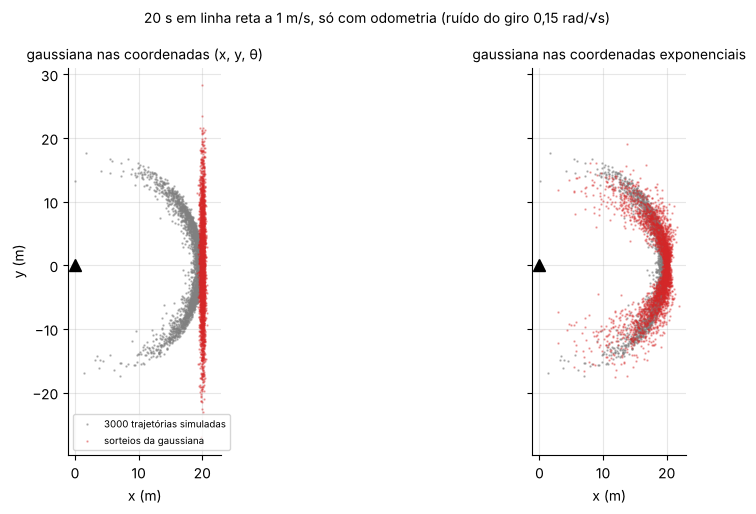

OK   a gaussiana exponencial cobre mais que a de coordenadas, nos três níveis:  diferença máxima = 0.00e+00


In [5]:
def experimento_banana(sig_w, sig_v=0.05, dt=0.05, T=20.0, v0=1.0, N=3000, semente=1):
    rng_b = np.random.default_rng(semente)
    n = int(T / dt)
    Qb = np.diag([sig_w**2 * dt, sig_v**2 * dt, 1e-10])
    q_nom, S, P, th = pose(0.0, 0j), np.zeros((3, 3)), np.zeros((3, 3)), 0.0
    for k in range(n):
        Eu = Exp(0.0, v0 * dt + 0j)
        A = Ad(Eu.conj()); S = A @ S @ A.T + Qb
        F = np.eye(3); F[0, 2] = -v0 * dt * np.sin(th); F[1, 2] = v0 * dt * np.cos(th)
        G = np.array([[0, dt], [0, 0], [dt, 0]])
        P = F @ P @ F.T + G @ np.diag([sig_w**2 / dt, sig_v**2 / dt]) @ G.T + np.diag([0, 1e-10, 0])
        q_nom = q_nom * Eu
    ths, ps = np.zeros(N), np.zeros(N, complex)
    for k in range(n):
        W = sig_w * np.sqrt(dt) * rng_b.standard_normal(N)
        V = (v0 + sig_v / np.sqrt(dt) * rng_b.standard_normal(N)) * dt
        ps = ps + np.exp(1j * ths) * V * np.exp(0.5j * W) * sinc(W / 2)
        ths = ths + W
    Si, Pi = np.linalg.inv(S), np.linalg.inv(P)
    xis = np.array([Log3(q_nom.conj() * pose(ths[i], ps[i])) for i in range(N)])
    E = np.c_[ps.real - translacao(q_nom).real, ps.imag - translacao(q_nom).imag, wrap(ths)]
    cob_exp = np.mean(np.einsum("ij,jk,ik->i", xis, Si, xis) < 7.81)
    cob_coord = np.mean(np.einsum("ij,jk,ik->i", E, Pi, E) < 7.81)
    return dict(q_nom=q_nom, S=S, P=P, ths=ths, ps=ps, cob_exp=cob_exp, cob_coord=cob_coord, xis=xis)

print(" ruído do giro    desvio do ângulo final   cobertura (coordenadas)   cobertura (exponencial)")
res = {}
for sw in [0.04, 0.08, 0.15]:
    r = experimento_banana(sw); res[sw] = r
    print(f"{sw:9.2f} rad/√s   {np.degrees(r['ths'].std()):14.0f}°   {r['cob_coord']:22.2f}   {r['cob_exp']:22.2f}")

r = res[0.15]
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
amostra_c = rng.multivariate_normal(np.zeros(3), r["P"], 3000)
amostra_e = rng.multivariate_normal(np.zeros(3), r["S"], 3000)
pts_c = translacao(r["q_nom"]) + amostra_c[:, 0] + 1j * amostra_c[:, 1]
pts_e = np.array([translacao(r["q_nom"] * Exp3(x)) for x in amostra_e])
for a_, pts, tit in zip(ax, [pts_c, pts_e], ["gaussiana nas coordenadas (x, y, θ)", "gaussiana nas coordenadas exponenciais"]):
    a_.plot(r["ps"].real, r["ps"].imag, ".", ms=1.5, color="gray", alpha=.5, label="3000 trajetórias simuladas")
    a_.plot(pts.real, pts.imag, ".", ms=1.5, color="tab:red", alpha=.35, label="sorteios da gaussiana")
    a_.plot(0, 0, "k^", ms=8); a_.set_aspect("equal"); a_.set_title(tit, fontsize=10); a_.set_xlabel("x (m)")
ax[0].set_ylabel("y (m)"); ax[0].legend(fontsize=7, loc="lower left")
fig.suptitle("20 s em linha reta a 1 m/s, só com odometria (ruído do giro 0,15 rad/√s)", fontsize=10)
plt.tight_layout(); plt.show()
confere("a gaussiana exponencial cobre mais que a de coordenadas, nos três níveis",
        all(res[s]["cob_exp"] > res[s]["cob_coord"] for s in res), True)

**Leitura.**
- Com pouco ruído (ângulo final com desvio de uns 11°), as duas gaussianas cobrem quase 95%: a banana ainda é quase uma elipse.
- Com mais ruído, a cobertura da gaussiana nas coordenadas despenca (abaixo de 25% no caso de 39°): a elipse é reta e larga, a nuvem é curva e fina, e a maior parte das trajetórias cai fora da elipse de 95%, embora a elipse cubra regiões onde não há trajetória nenhuma (a figura da esquerda).
- A gaussiana exponencial, levada ao plano pela $\mathrm{Exp}$, já sai **curva** (a figura da direita): os sorteios desenham a banana. A cobertura também cai com o ruído, mas bem menos (81% contra 59% no nível intermediário). Ela não chega a 95% porque a propagação de primeira ordem subestima a variação ao longo do caminho (a banana encurta: o robô que se desvia termina mais perto do ponto de partida, um efeito de segunda ordem). Long, Wolfe, Mashner e Chirikjian (2012, *The banana distribution is Gaussian*) mostram que, com a propagação de segunda ordem, a gaussiana exponencial descreve a nuvem quase perfeitamente.

É a "banana" do notebook II(c) de novo, agora com uma resposta: **a incerteza de uma pose deve ser escrita no espaço tangente do grupo**, onde ela é quase gaussiana. É o que o estado de erro do ESKF faz.

---

## 5. Espaço de estados para a etapa (d)

O filtro da etapa (d) guarda a pose estimada $\hat q$ e a covariância de um **erro** $\xi\in\mathbb R^3$. Em $SE(2)$, há duas maneiras de definir esse erro, porque a multiplicação não comuta:

| erro | definição | predição com a odometria $u$ ($\hat q\leftarrow\hat q\,\mathrm{Exp}(u)$) |
|---|---|---|
| **no corpo** (à direita) | $q=\hat q\,\mathrm{Exp}(\xi)$ | $\xi\leftarrow\mathrm{Ad}_{\mathrm{Exp}(-u)}\,\xi+n$ |
| **no mundo** (à esquerda) | $q=\mathrm{Exp}(\xi)\,\hat q$ | $\xi\leftarrow\xi+\mathrm{Ad}_{\hat q}\,n$ |

Aqui $n$ é o ruído da odometria, no referencial do corpo. A matriz adjunta $\mathrm{Ad}_q$ é a que "muda o referencial de uma velocidade": $q\,\mathrm{Exp}(\xi)\,q^{-1}=\mathrm{Exp}(\mathrm{Ad}_q\xi)$. Em coordenadas $(\omega,v_x,v_y)$, para a pose $(\theta,t)$:

$$\mathrm{Ad}_q=\begin{bmatrix}1&0&0\\t_y&\cos\theta&-\sin\theta\\-t_x&\sin\theta&\cos\theta\end{bmatrix}.$$

Em notação complexa, $\mathrm{Ad}_q(\omega,v)=(\omega,\ e^{i\theta}v-i\omega t)$: a velocidade de translação é girada para o mundo, e o giro, visto de longe da origem, também translada.

**Uma curiosidade importante.** Com o erro no mundo, a predição **não depende da odometria nem da pose estimada**, a não ser pelo ruído: o erro fica parado. Barrau e Bonnabel chamam isso de **filtro de Kalman estendido invariante**: a matriz de transição do erro é exatamente a identidade, sem linearização em torno de uma estimativa possivelmente errada. A célula confere a fórmula da adjunta e a relação entre os dois erros, $\xi_{\text{mundo}}=\mathrm{Ad}_{\hat q}\,\xi_{\text{corpo}}$.

In [6]:
q_t = pose(0.9, 2.0 - 1.5j)
for _ in range(3):
    xi = rng.normal(size=3)
    esq = q_t * Exp3(xi) * q_t.conj(); dir_ = Exp3(Ad(q_t) @ xi)
    confere("q Exp(ξ) q⁻¹ = Exp(Ad_q ξ)", [angulo(esq), translacao(esq)], [angulo(dir_), translacao(dir_)], tol=1e-13)

q_hat = pose(0.4, 1.0 + 2.0j)
q_ver = q_hat * Exp3(np.array([0.05, -0.1, 0.07]))
xi_corpo = Log3(q_hat.conj() * q_ver)
xi_mundo = Log3(q_ver * q_hat.conj())
confere("ξ_mundo = Ad_q̂ ξ_corpo", xi_mundo, Ad(q_hat) @ xi_corpo, tol=1e-13)

# a predição dos dois erros, com a mesma odometria, dá a mesma incerteza vista do mesmo lugar
u = np.array([0.02, 0.05, 0.0]); Qb = np.diag([1e-4, 1e-4, 1e-6])
S_corpo = np.diag([0.01, 0.04, 0.04]); S_mundo = Ad(q_hat) @ S_corpo @ Ad(q_hat).T
q_prox = q_hat * Exp3(u)
A_c = Ad(Exp3(u).conj()); S_corpo_p = A_c @ S_corpo @ A_c.T + Qb
S_mundo_p = S_mundo + Ad(q_prox) @ Qb @ Ad(q_prox).T
confere("as duas predições descrevem a mesma incerteza (Σ_mundo = Ad Σ_corpo Adᵀ)", S_mundo_p, Ad(q_prox) @ S_corpo_p @ Ad(q_prox).T, tol=1e-15)

OK   q Exp(ξ) q⁻¹ = Exp(Ad_q ξ):  diferença máxima = 1.11e-16
OK   q Exp(ξ) q⁻¹ = Exp(Ad_q ξ):  diferença máxima = 2.00e-16
OK   q Exp(ξ) q⁻¹ = Exp(Ad_q ξ):  diferença máxima = 4.44e-16
OK   ξ_mundo = Ad_q̂ ξ_corpo:  diferença máxima = 5.41e-16
OK   as duas predições descrevem a mesma incerteza (Σ_mundo = Ad Σ_corpo Adᵀ):  diferença máxima = 1.39e-17


**Leitura.** Na **predição**, os dois erros são equivalentes: descrevem a mesma incerteza, cada um no seu referencial. A diferença aparece na **correção**: o jacobiano de uma medida depende do tipo de erro, e, para certos pares de erro e sensor, ele não depende da estimativa. O notebook V(d) mostra quando isso faz diferença.

---

## 6. Exercícios

1. **Magnus com três pontos.** Escreva o método de Magnus de ordem 6 (três pontos de Gauss, com colchetes aninhados) e meça a ordem. Quantos colchetes ele precisa?
2. **O colchete na nave.** Na seção 3, troque o Magnus de ordem 4 pelo ponto médio. Onde as duas trajetórias se separam mais: nos trechos de empuxo, de giro, ou nos trechos em que as duas coisas acontecem juntas? Por quê?
3. **Estacionar.** Usando o colchete, planeje uma sequência de quatro movimentos (frente, gira, ré, desgira) que desloque um carro 0,5 m de lado sem mudar a orientação final. Confira com dual-complexos.
4. **A banana de segunda ordem.** Acrescente à propagação da seção 4 a correção de segunda ordem para a média: o robô que se desvia termina, em média, mais perto do ponto de partida. Estime a média de $\xi$ pela simulação e veja quanto ela corrige a cobertura.
5. **Erro no mundo e a banana.** Refaça a figura da seção 4 com a gaussiana definida pelo erro no mundo, $q=\mathrm{Exp}(\xi)\hat q$, com $\Sigma_{\text{mundo}}=\mathrm{Ad}_{\hat q}\Sigma\mathrm{Ad}_{\hat q}^\top$. A nuvem de sorteios é a mesma? Por quê?